# How `build_3d_segmentation_v2.py` works (version 2)

Version 1 (`build_3d_segmentation.py`, explained in `build_3d_segmentation_explained.ipynb`) copies,
for every output voxel, the label of the nearest histology section. Version 2 keeps the same inputs,
the same output grid and the same mosaic, but changes **what happens between sections** and uses
the **MRI** to remove labels outside the brain.

| step | version 1 | version 2 |
|---|---|---|
| between two sections | copy the nearest one (staircase) | **shape-based interpolation** (sections 2-4) |
| empty / partly labelled sections | copied as they are (block gaps) | **skipped and bridged** from the usable sections (section 5) |
| overlap between blocks | closest section wins | closest **usable** section wins (section 7) |
| labels where the MRI has no tissue | kept | **removed**, except labels the MRI cannot see (section 8) |
| unlabelled voxels inside the brain | left empty | left empty; optional fill that is **off by default** (section 9) |

Contents:
1. What version 1 leaves to fix
2. The signed distance map of a label
3. Shape-based interpolation between two sections (toy and real examples)
4. A label present in only one of the two sections
5. Missing sections and how they are bridged
6. One whole block: `reconstruct_block`
7. Mosaic of several blocks and the `steps` map
8. Trimming with the MRI
9. The optional MRI fill, and why it is off
10. The complete result, measured against version 1

The notebook reads the data but **writes nothing**. It takes about 5 minutes to run.

In [10]:
import os, sys, csv, itertools, time
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, to_rgb
from matplotlib.patches import Rectangle
from scipy import ndimage as ndi

%matplotlib inline
plt.rcParams["figure.dpi"] = 90

HERE = os.path.abspath(".")
sys.path.insert(0, HERE)
import build_3d_segmentation_v2 as V2        # the script explained here

CASE_DIR = os.path.join(HERE, "..", "NextBrain-Case-1", "P57-16")
LUT_FILE = os.path.join(HERE, "..", "..", "3dAtlas", "lut.freeview.txt")
OUT_V1 = os.path.join(HERE, "outputs", "P57-16_seg_0.2mm.nii.gz")
OUT_V2 = os.path.join(HERE, "outputs", "P57-16_seg_0.2mm_v2.nii.gz")
RES = 0.2
# default parameters of the script
MIN_SECTION_FRAC, SDT_CAP_MM, STRIDE, KEEP_OUTSIDE_FRAC, MAX_FILL_MM = 0.3, 1.0, 1, 0.25, 2.0

blocks_dir = os.path.join(CASE_DIR, "labels_blocks")
block_name = dict(csv.reader(open(os.path.join(CASE_DIR, "block2slab_mapping.csv"))))
load_block = lambda b: nib.load(os.path.join(blocks_dir, str(b), "LABELS.nii.gz"))
mri = nib.load(os.path.join(CASE_DIR, "mri_rotated", "mri.nii.gz"))
shape, affine = V2.target_grid(mri, RES)     # same grid as version 1
print("output grid", shape)

output grid (473, 934, 753)


In [11]:
# ---- display helpers ---------------------------------------------------------------------
BG = (0.45, 0.45, 0.45)      # background drawn mid-grey (white matter is almost white, ventricle almost black)

def load_lut(path):
    names, rgb = {}, np.full((4096, 3), 0.5)
    for line in open(path):
        p = line.split()
        if len(p) >= 5 and p[0].isdigit():
            names[int(p[0])] = p[1]; rgb[int(p[0])] = [int(v) / 255 for v in p[2:5]]
    rgb[0] = BG
    return names, rgb
NAMES, RGB = load_lut(LUT_FILE)

def show_lab(ax, a2d, extent=None, title=None, rgb=None):
    ax.imshow((RGB if rgb is None else rgb)[a2d.T], origin="lower", interpolation="nearest", extent=extent)
    if title: ax.set_title(title, fontsize=10)

def show_img(ax, a2d, extent=None, title=None, **kw):
    im = ax.imshow(a2d.T, origin="lower", interpolation="nearest", extent=extent, **kw)
    if title: ax.set_title(title, fontsize=10)
    return im

def overlay(ax, mask2d, color, extent=None, alpha=0.9):
    rgba = np.zeros(mask2d.T.shape + (4,)); rgba[mask2d.T] = (*to_rgb(color), alpha)
    ax.imshow(rgba, origin="lower", interpolation="nearest", extent=extent)

def ext_of(sj, sk):
    return [sj.start, sj.stop, sk.start, sk.stop]

STEP_CMAP = ListedColormap([BG, "#c6dbef", "tab:orange", "magenta", "red"])
STEP_NAMES = {1: "interpolated", 2: "bridged", 3: "MRI fill", 4: "trimmed"}
TOY_RGB = np.array([BG, to_rgb("#f2f1f0"), to_rgb("tab:olive"), to_rgb("tab:red")])

def resample_block_v1(img):
    """Version 1 for one block (nearest section), for comparison. See the first notebook."""
    lab = np.asanyarray(img.dataobj); nb = np.array(lab.shape[:3])
    vox = (V2.corners_ras(nb, img.affine) - affine[:3, 3]) / RES
    lo = np.clip(np.floor(vox.min(0)).astype(int), 0, shape); hi = np.clip(np.ceil(vox.max(0)).astype(int) + 1, 0, shape)
    M = np.linalg.inv(img.affine) @ affine
    ii, jj, kk = (np.arange(lo[a], hi[a], dtype=np.float32).reshape([-1 if a == q else 1 for q in range(3)]) for a in range(3))
    c = [M[r, 0] * ii + M[r, 1] * jj + M[r, 2] * kk + M[r, 3] for r in range(3)]
    idx = [np.rint(x).astype(np.int32) for x in c]
    inside = np.ones(idx[0].shape, bool)
    for a in range(3): inside &= (idx[a] >= 0) & (idx[a] < nb[a])
    dist = (np.abs(c[2] - idx[2]) * np.linalg.norm(img.affine[:3, 2])).astype(np.float32); dist[~inside] = np.inf
    vals = np.zeros(inside.shape, np.uint16); vals[inside] = lab[idx[0][inside], idx[1][inside], idx[2][inside]]
    return tuple(slice(a, b) for a, b in zip(lo, hi)), vals, dist

## 1. What version 1 leaves to fix

A block is a stack of sections with 0.1 mm pixels in-plane but 0.33-0.8 mm between sections.
Version 1 gives each output voxel the label of the nearest section, so:
- every section is repeated over 2-4 voxels and boundaries move in steps (**staircase**);
- if a section of the block file is empty or half labelled, the output is empty there (**block gap**).

Below, block 8 (A2.3, sections every 0.72 mm) resampled by version 1 and seen from the side.

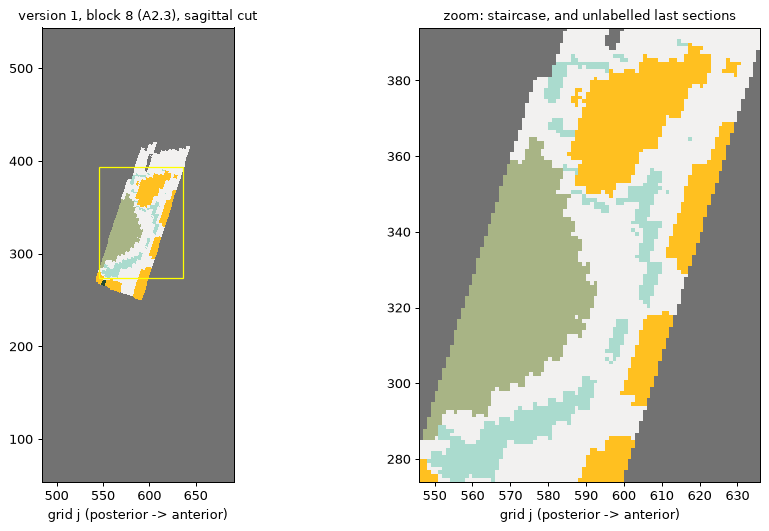

In [12]:
EXAMPLE = 8
img = load_block(EXAMPLE); lab = np.asanyarray(img.dataobj)
pix = float(np.linalg.norm(img.affine[:3, 0])); dz = float(np.linalg.norm(img.affine[:3, 2]))
box1, v1_blk, v1_dist = resample_block_v1(img)
IX = v1_blk.shape[0] // 2                                  # sagittal cut through the middle of the box
fg = np.argwhere(v1_blk[IX] > 0); cj, ck = np.median(fg, 0).astype(int)
ZJ, ZK = slice(max(cj - 45, 0), cj + 45), slice(max(ck - 60, 0), ck + 60)      # zoom window (box coordinates)
gext = lambda sj, sk: [box1[1].start + sj.start, box1[1].start + sj.stop, box1[2].start + sk.start, box1[2].start + sk.stop]
full = (slice(0, v1_blk.shape[1]), slice(0, v1_blk.shape[2]))

fig, axs = plt.subplots(1, 2, figsize=(11, 6), gridspec_kw=dict(width_ratios=[1, 1.5]))
show_lab(axs[0], v1_blk[IX], gext(*full), f"version 1, block {EXAMPLE} ({block_name[str(EXAMPLE)]}), sagittal cut")
axs[0].add_patch(Rectangle((gext(ZJ, ZK)[0], gext(ZJ, ZK)[2]), 90, 120, fill=False, ec="yellow"))
show_lab(axs[1], v1_blk[IX][ZJ, ZK], gext(ZJ, ZK), "zoom: staircase, and unlabelled last sections")
for ax in axs: ax.set_xlabel("grid j (posterior -> anterior)")
plt.tight_layout(); plt.show()

## 2. The signed distance map of a label

To interpolate **shapes** (not intensities) the script first converts every label of a section into
a **signed distance map**: for each pixel, the distance in mm to the border of the label, **positive
inside** and **negative outside**. The border of the label is where the map is zero.

`section_sdt(sec, pix_mm, cap)` returns one map per label present in the section, **background
included** (background competes with the labels like any other class). The distances are clipped to
± `cap` (`--sdt-cap-mm`, default 1 mm): far from the border the exact distance does not matter.

Example: the putamen in one section of the block.

section 8: maps for labels [0, 7, 48, 50, 68, 79, 101, 102, 113, 114, 2012, 2014, 2018, 2035]
label 79 (putamen): raw distances from -48.3 to 4.7 mm, after clipping from -1.0 to 1.0 mm


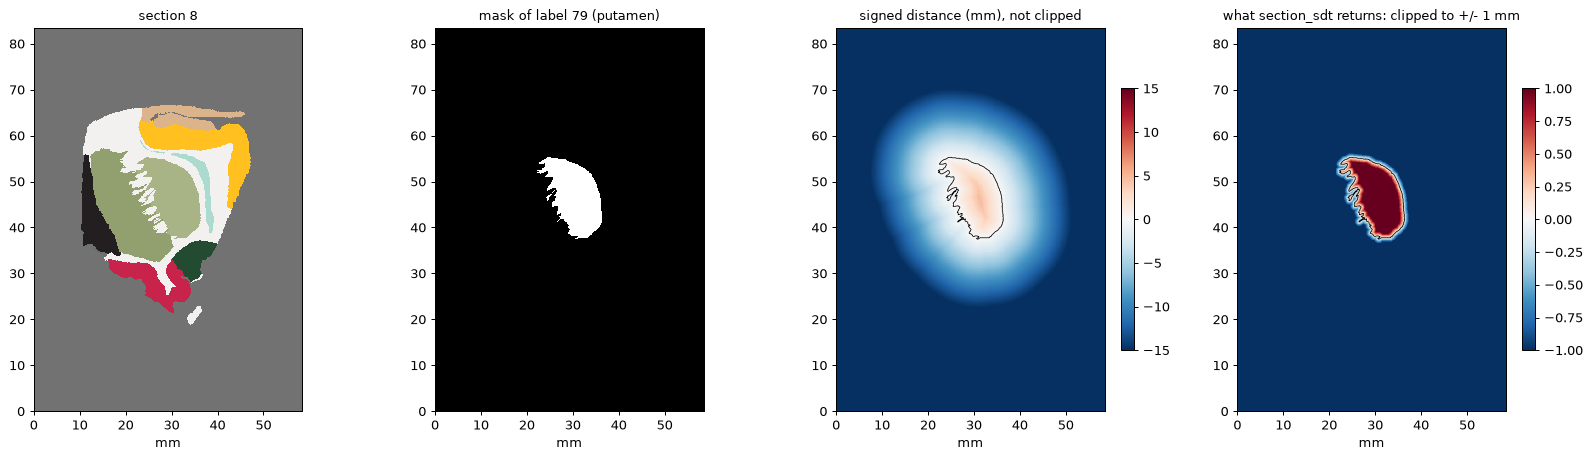

In [13]:
K = 8
sec = lab[:, :, K]
sdt = V2.section_sdt(sec, pix, SDT_CAP_MM)                 # dict: label -> signed distance map (float32)
print(f"section {K}: maps for labels {sorted(sdt)}")
L = 79
m = sec == L
raw = (ndi.distance_transform_edt(m) - ndi.distance_transform_edt(~m)) * pix      # before clipping
print(f"label {L} ({NAMES[L]}): raw distances from {raw.min():.1f} to {raw.max():.1f} mm, "
      f"after clipping from {sdt[L].min():.1f} to {sdt[L].max():.1f} mm")

e = [0, sec.shape[0] * pix, 0, sec.shape[1] * pix]
fig, axs = plt.subplots(1, 4, figsize=(18, 5.2))
show_lab(axs[0], sec, e, f"section {K}")
show_img(axs[1], m, e, f"mask of label {L} ({NAMES[L]})", cmap="gray")
im = show_img(axs[2], raw, e, "signed distance (mm), not clipped", cmap="RdBu_r", vmin=-15, vmax=15); plt.colorbar(im, ax=axs[2], fraction=0.04)
im = show_img(axs[3], sdt[L], e, "what section_sdt returns: clipped to +/- 1 mm", cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar(im, ax=axs[3], fraction=0.04)
for ax in axs[2:]: ax.contour(m.T, [0.5], colors="k", linewidths=0.6, extent=e)
for ax in axs: ax.set_xlabel("mm")
plt.tight_layout(); plt.show()

## 3. Shape-based interpolation between two sections

Take an output voxel that lies between section `a` and section `b`, at a fraction `t` of the way
(`t = 0` on `a`, `t = 1` on `b`). It projects on the same in-plane pixel `(x, y)` of both sections.
For each label `l`:

```
value_l = (1 - t) * sdt_a[l][x, y]  +  t * sdt_b[l][x, y]
```

and the voxel gets **the label with the largest value**. Blending the two distance maps moves the
zero level (the border) gradually from its position in `a` to its position in `b`, so a structure
changes shape smoothly instead of jumping half-way.

The function below is the inner loop of `reconstruct_block`, written for two whole sections so that
it can be shown as an image.

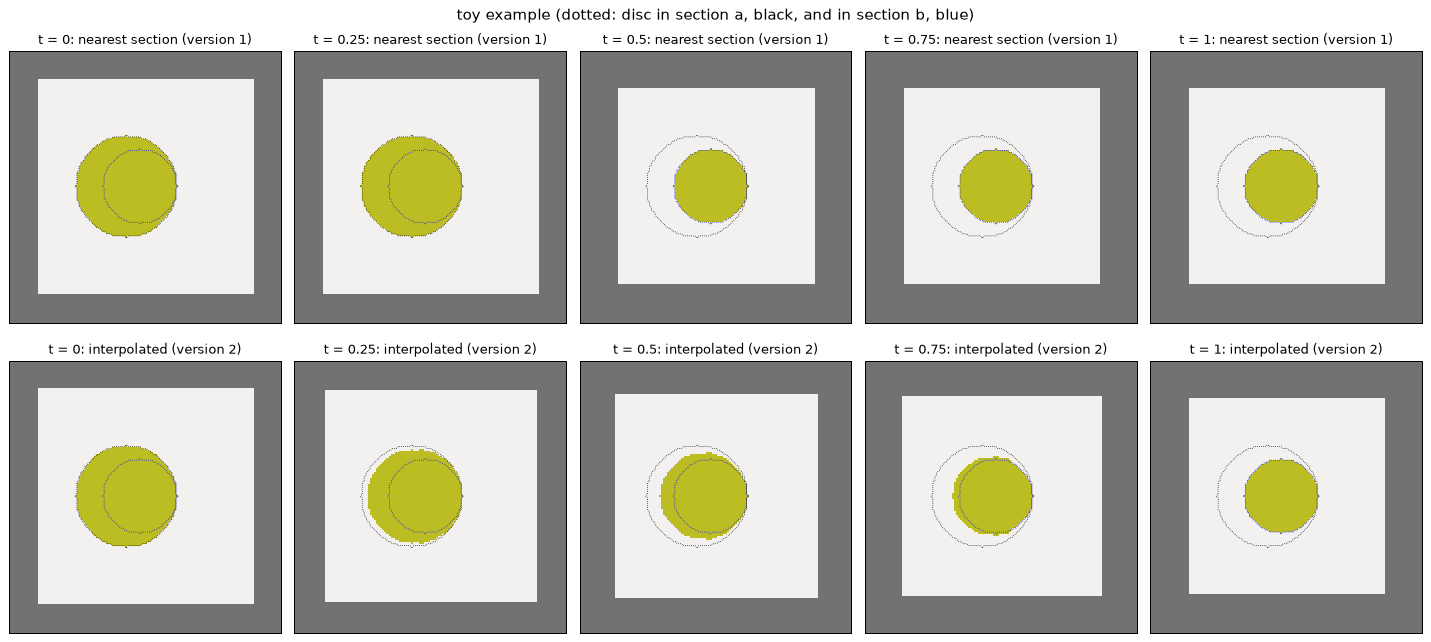

In [14]:
def interpolate_pair(sec_a, sec_b, t, pix=0.1, cap=SDT_CAP_MM, absent="fade"):
    """Label image at fraction t between two sections (same rule as reconstruct_block).
    absent='fade' is the rule of the script; absent='cap' is the naive alternative (section 4)."""
    sa, sb = V2.section_sdt(sec_a, pix, cap), V2.section_sdt(sec_b, pix, cap)
    best_val = np.full(sec_a.shape, -np.inf, np.float32); best_lab = np.zeros(sec_a.shape, np.uint16)
    for l in sorted(set(sa) | set(sb)):
        if l in sa and l in sb:
            va, vb = sa[l], sb[l]
        elif l in sa:
            va = sa[l]; vb = -np.maximum(np.abs(va), pix) if absent == "fade" else np.full_like(va, -cap)
        else:
            vb = sb[l]; va = -np.maximum(np.abs(vb), pix) if absent == "fade" else np.full_like(vb, -cap)
        val = (1 - t) * va + t * vb
        better = val > best_val
        best_val[better] = val[better]; best_lab[better] = l
    return best_lab

def toy(cx, r, half):
    """Toy section, 0.1 mm pixels: a square of 'tissue' (label 1) with a disc (label 2) inside."""
    yy, xx = np.mgrid[:140, :140]
    s = np.zeros((140, 140), np.uint16)
    s[(abs(xx - 70) <= half) & (abs(yy - 70) <= half)] = 1
    s[(yy - cx) ** 2 + (xx - 70) ** 2 <= r ** 2] = 2
    return s

sec_a, sec_b = toy(60, 26, 55), toy(67, 19, 50)     # the disc shrinks and moves 0.7 mm, the tissue edge moves 0.5 mm
ts = [0, 0.25, 0.5, 0.75, 1]
fig, axs = plt.subplots(2, 5, figsize=(16, 7.4))
for ax0, ax1, t in zip(axs[0], axs[1], ts):
    show_lab(ax0, sec_a if t < 0.5 else sec_b, rgb=TOY_RGB, title=f"t = {t}: nearest section (version 1)")
    show_lab(ax1, interpolate_pair(sec_a, sec_b, t), rgb=TOY_RGB, title=f"t = {t}: interpolated (version 2)")
    for ax in (ax0, ax1):
        ax.contour((sec_a == 2).T, [0.5], colors="k", linewidths=0.6, linestyles=":"); ax.contour((sec_b == 2).T, [0.5], colors="b", linewidths=0.6, linestyles=":")
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("toy example (dotted: disc in section a, black, and in section b, blue)"); plt.tight_layout(h_pad=2.5); plt.show()

Top row: nearest section shows shape `a` up to the middle and then jumps to shape `b`.
Bottom row: the disc shrinks and moves progressively, and so does the outer edge of the tissue.

The same thing in one dimension, along a line through the disc: the blended map crosses zero at an
intermediate position.

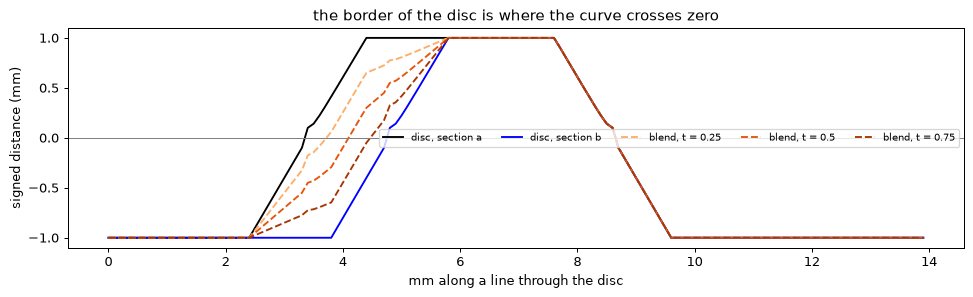

In [15]:
sa, sb = V2.section_sdt(sec_a, 0.1, SDT_CAP_MM), V2.section_sdt(sec_b, 0.1, SDT_CAP_MM)
x = np.arange(140) * 0.1
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(x, sa[2][:, 70], "k", label="disc, section a"); ax.plot(x, sb[2][:, 70], "b", label="disc, section b")
for t, c in ((0.25, "#fdae6b"), (0.5, "#e6550d"), (0.75, "#a63603")):
    ax.plot(x, (1 - t) * sa[2][:, 70] + t * sb[2][:, 70], color=c, ls="--", label=f"blend, t = {t}")
ax.axhline(0, color="gray", lw=0.8); ax.set_xlabel("mm along a line through the disc"); ax.set_ylabel("signed distance (mm)")
ax.set_title("the border of the disc is where the curve crosses zero"); ax.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

### The limit of the method: the cap

The curves above are flat at ± 1 mm because of the clipping. If a structure moves **more than the
cap** between two sections, the two positive regions do not overlap any more and the blend cannot
"slide" the structure: it fades out in `a` and fades in in `b`, which is what nearest-section does.
So the result is never worse than version 1, but for fast-moving thin structures it is not better.

A larger cap would slide further, but the first tests with 3 mm made small nuclei lose 30-60% of
their volume (large structures with big distance values win over small ones), so the default is 1 mm.

**This limit is not solved in version 2.** The cap of 1 mm is a compromise: structures that move
less than 1 mm between two sections are interpolated, the others behave as in version 1.

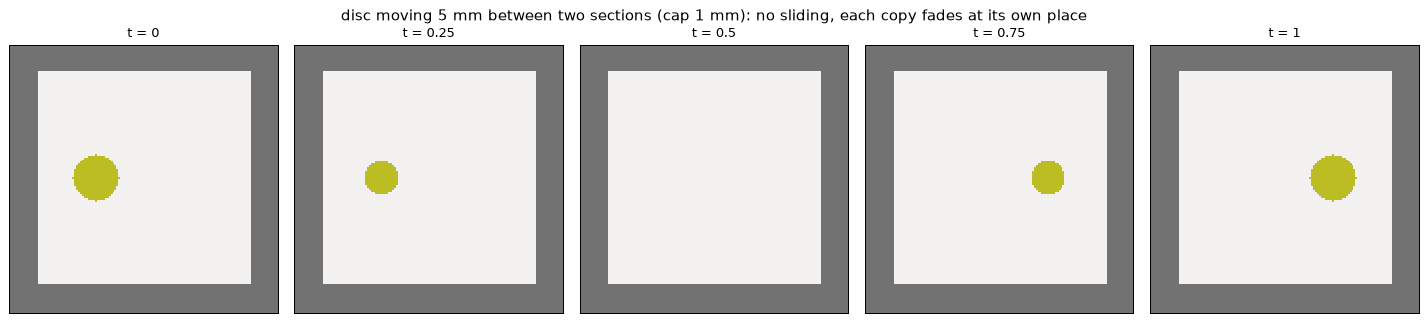

In [16]:
far_a, far_b = toy(45, 12, 55), toy(95, 12, 55)      # the disc moves 5 mm: more than the cap
fig, axs = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, t in zip(axs, ts):
    show_lab(ax, interpolate_pair(far_a, far_b, t), rgb=TOY_RGB, title=f"t = {t}"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("disc moving 5 mm between two sections (cap 1 mm): no sliding, each copy fades at its own place"); plt.tight_layout(); plt.show()

### Real sections

Two consecutive sections of the block and what the script produces half-way between them.

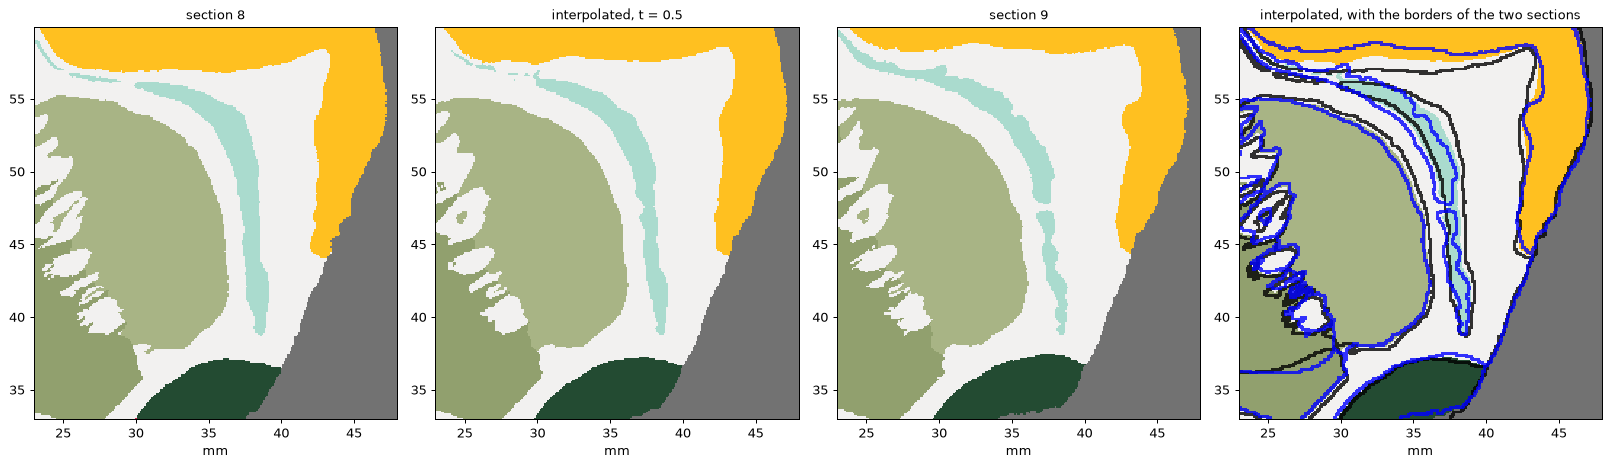

pixels where the two sections have a different label: 4.2% of the section


In [17]:
a, b = lab[:, :, K], lab[:, :, K + 1]
mid = interpolate_pair(a, b, 0.5, pix)
win = (slice(230, 480), slice(330, 600))               # in-plane zoom (pixels)
e = [win[0].start * pix, win[0].stop * pix, win[1].start * pix, win[1].stop * pix]
fig, axs = plt.subplots(1, 4, figsize=(18, 5.4))
show_lab(axs[0], a[win], e, f"section {K}"); show_lab(axs[1], mid[win], e, "interpolated, t = 0.5"); show_lab(axs[2], b[win], e, f"section {K+1}")
show_lab(axs[3], mid[win], e, "interpolated, with the borders of the two sections")
for s, c in ((a, "k"), (b, "b")):
    edges = ndi.morphological_gradient(s[win], size=3) > 0
    overlay(axs[3], edges, c, e, 0.8)
for ax in axs: ax.set_xlabel("mm")
plt.tight_layout(); plt.show()
print(f"pixels where the two sections have a different label: {(a != b).mean()*100:.1f}% of the section")

In the last panel the borders of section `a` are black and those of section `b` blue: the borders of
the interpolated image fall between them.

## 4. A label present in only one of the two sections

Small nuclei often appear in one section and not in the next one. Then there is no distance map for
that label in the other section. What value should it have there?

- Naive choice: "very far outside", i.e. `-cap` everywhere. The blend of the label is pulled down
  quickly and the structure **shrinks fast**: small structures lose a lot of volume.
- Choice of the script: `-max(|v|, one pixel)`, where `v` is the value of the label in the section
  that has it. In words: in the section where the label is missing, it is given **its own value with
  the sign changed to negative**.
  - Pixel **inside** the structure (`v > 0`): the other section gets `-v`, and the blend is
    `(1 - t) v + t (-v) = (1 - 2t) v`. It is `v` at `t = 0`, zero at `t = 0.5` and `-v` at `t = 1`.
    The label's own value says "inside" during the first half of the way and "outside" during the
    second half, which is what nearest-section does.
  - Pixel **outside** the structure (`v < 0`): `-|v|` is `v` itself, so the blend is
    `(1 - t) v + t v = v`. It does not change with `t`.
  - `max(…, one pixel)` only makes sure that the value given to the other section is never zero.

  The difference with the naive choice is the **size of the penalty**: `-cap` is always -1 mm, while
  `-v` is small for a small structure (a strip 0.3 mm wide has `v` ≤ 0.15 mm). A thin structure is
  not pushed out harder than a thick one.

The formula only gives the label's **own** value. A pixel gets the label with the **largest** blended
value, so what happens to the structure also depends on the labels around it:
- If the surrounding label is the same in both sections (the toy below), its value at the pixels of
  the structure rises steadily, the structure **shrinks** as `t` grows and is gone at `t = 0.5`. It
  shrinks more slowly than with the naive choice.
- If the surroundings also change between the two sections (the usual case in real data, shown after
  the toy), their blended values are low half-way. The structure can then keep its size, **grow** a
  little, or survive **beyond** `t = 0.5`. Its size is not guaranteed.

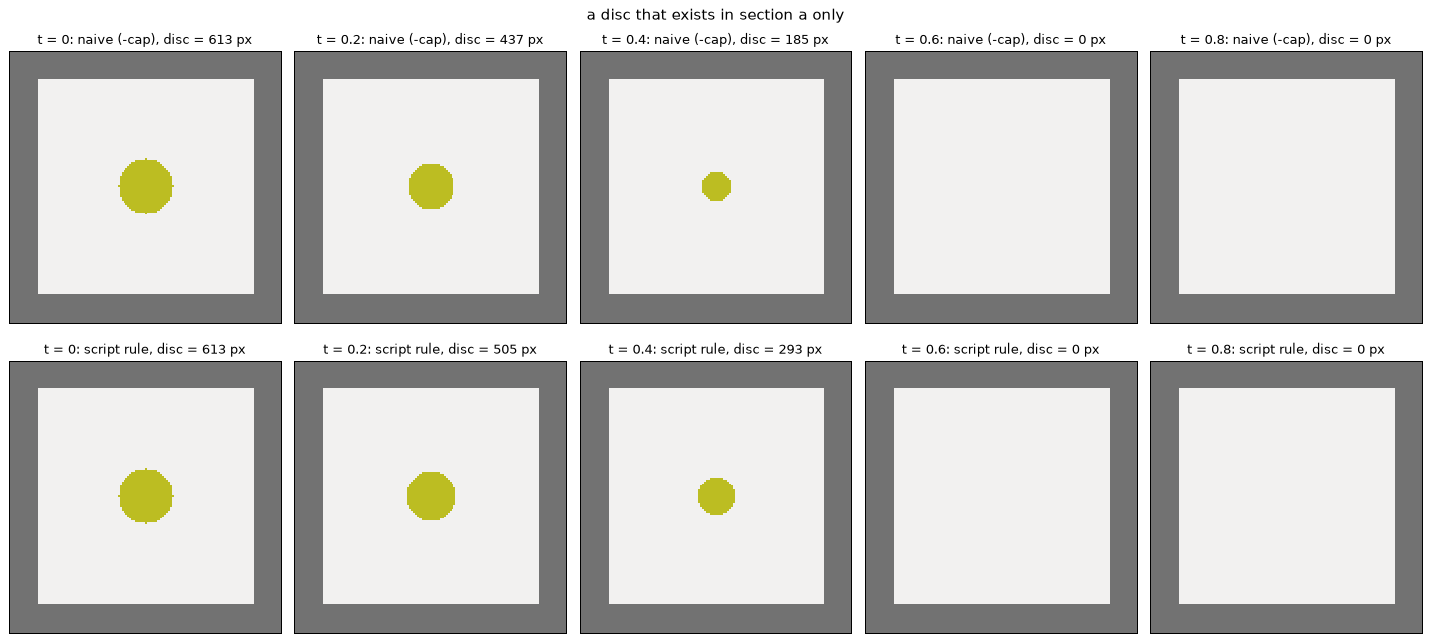

In [18]:
only_a = toy(70, 14, 55); none_b = toy(70, 0, 55); none_b[none_b == 2] = 1      # the disc exists only in section a
ts2 = [0, 0.2, 0.4, 0.6, 0.8]
fig, axs = plt.subplots(2, 5, figsize=(16, 7.4))
for ax0, ax1, t in zip(axs[0], axs[1], ts2):
    n0 = interpolate_pair(only_a, none_b, t, absent="cap"); n1 = interpolate_pair(only_a, none_b, t, absent="fade")
    show_lab(ax0, n0, rgb=TOY_RGB, title=f"t = {t}: naive (-cap), disc = {(n0 == 2).sum()} px")
    show_lab(ax1, n1, rgb=TOY_RGB, title=f"t = {t}: script rule, disc = {(n1 == 2).sum()} px")
    for ax in (ax0, ax1): ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("a disc that exists in section a only"); plt.tight_layout(h_pad=2.5); plt.show()

### The same comparison on real sections

The toy disc is large. In the real block the labels that exist in only one section are small, and
there the two rules give very different results. Three examples from block 8, the first one in the
pair of sections `K`, `K + 1` used above:

| pair of sections | label present in only one | size in that section |
|---|---|---|
| 8 - 9 | anterior olfactory nucleus (99), only in section 9 | 479 px = 4.8 mm² |
| 4 - 5 | olfactory tubercle (100), only in section 4 | 126 px = 1.3 mm², a strip 0.2-0.3 mm wide |
| 6 - 7 | septum pellucidum (68), only in section 7 | 223 px = 2.2 mm² |

`u` is the fraction of the way from the section that **has** the label (`u = 0`) to the section that
does not (`u = 1`). Top row of each figure: naive rule. Bottom row: rule of the script. The label is
painted in magenta, the black line is its outline in its section; the number in each title is its area in pixels.

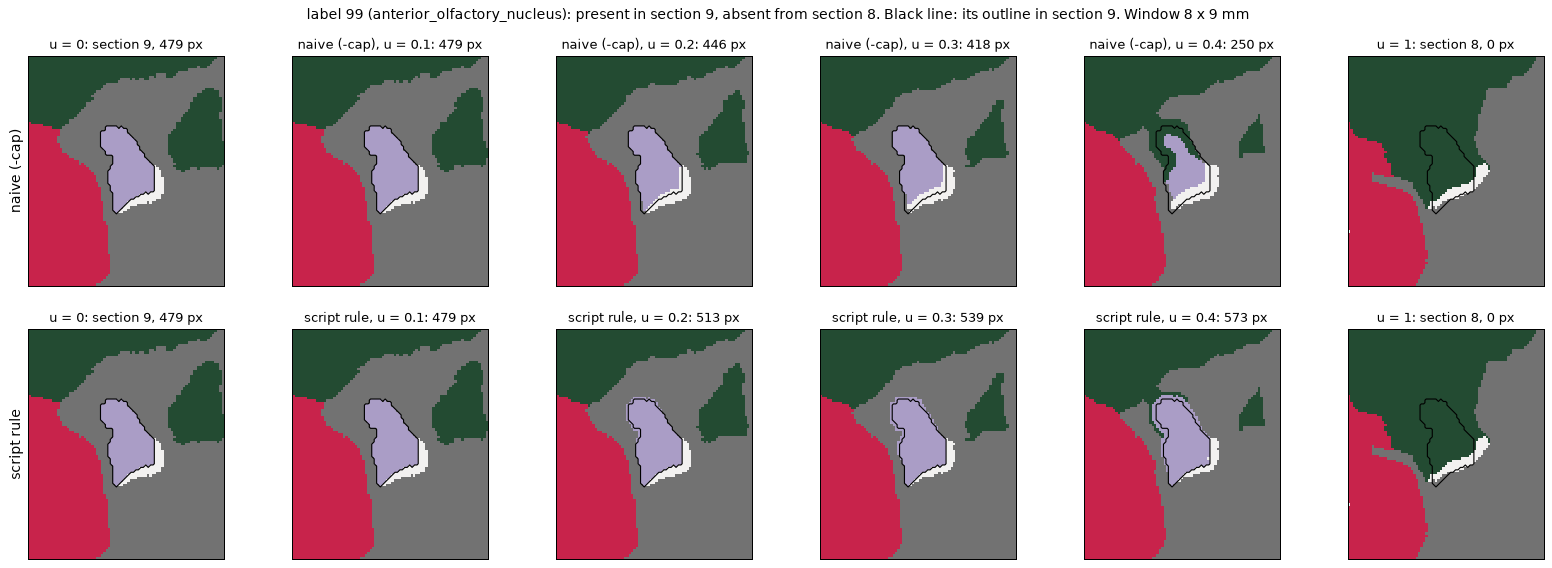

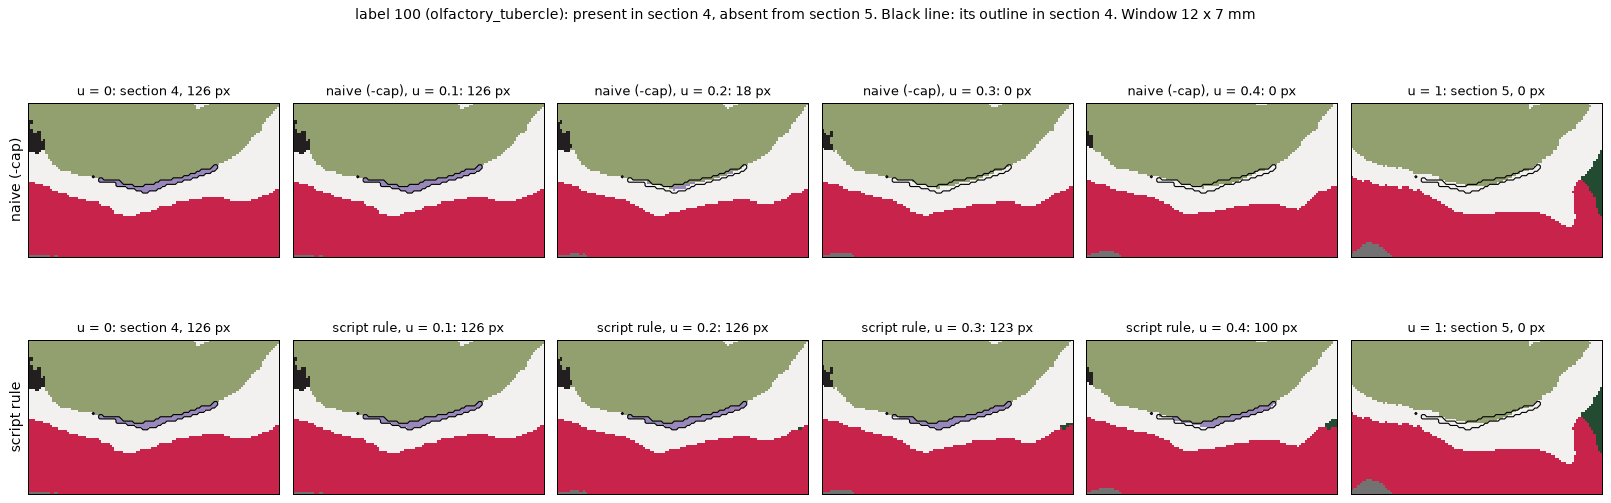

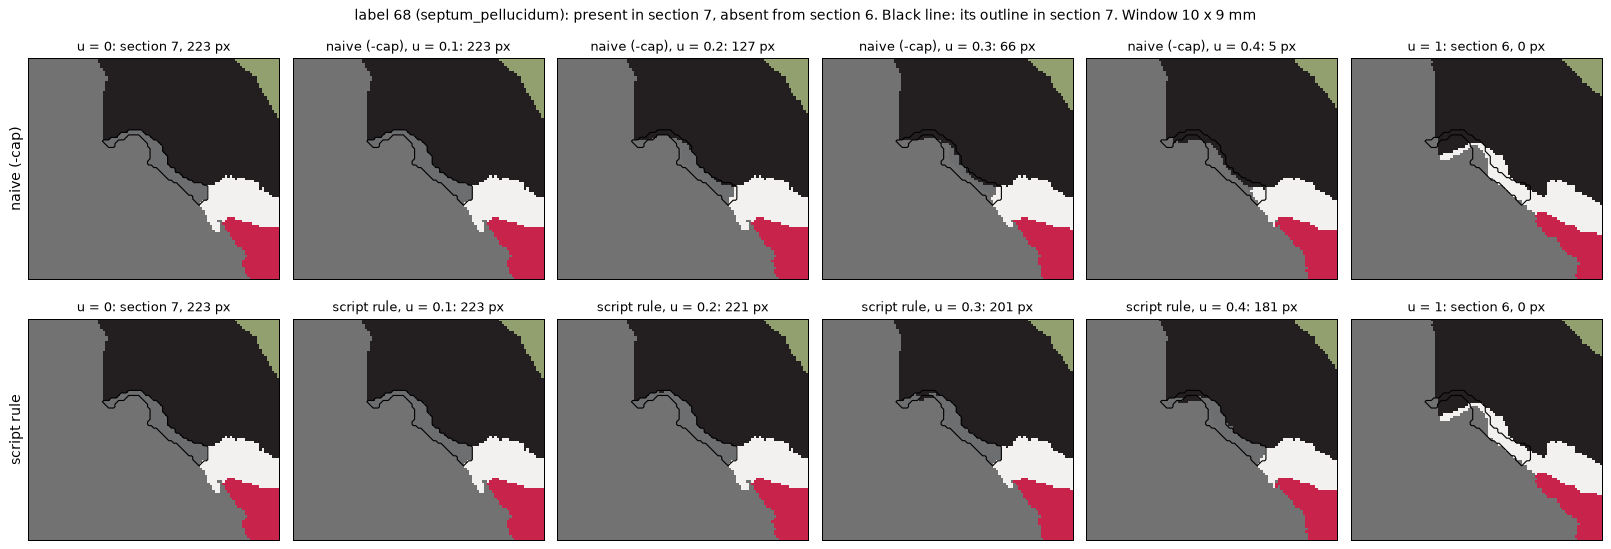

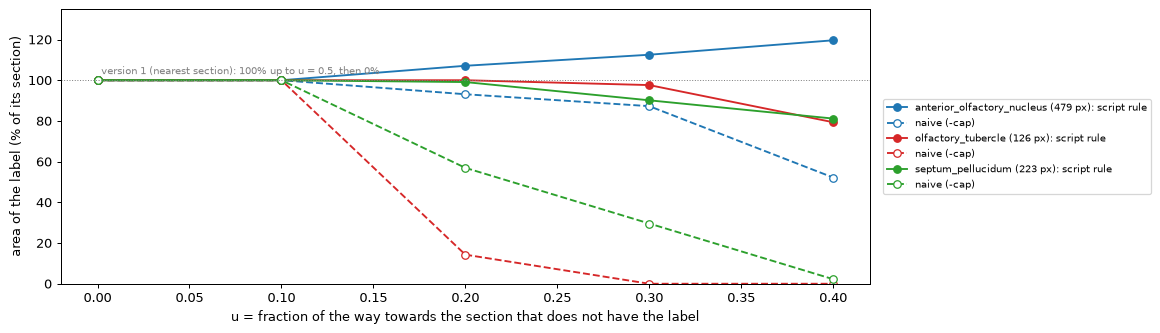

In [19]:
def one_section_only(k, l, us=(0, 0.2, 0.4, 0.5, 0.6, 0.8), show=30, pad=20):
    """Label l exists in only one of the sections k, k+1 of the block. Compares the two rules at a fraction u
    of the way from the section that has the label (u = 0) to the section that does not (u = 1)."""
    in_a = bool((lab[:, :, k] == l).any()); k_has, k_not = (k, k + 1) if in_a else (k + 1, k)
    xs, ys = np.nonzero(lab[:, :, k_has] == l)
    m = show + pad                                     # the maps are computed on a crop larger than what is drawn,
    crop = (slice(max(xs.min() - m, 0), xs.max() + m), slice(max(ys.min() - m, 0), ys.max() + m))   # so the crop edge has no effect
    a, b = lab[:, :, k][crop], lab[:, :, k + 1][crop]
    has, hasnot = (a, b) if in_a else (b, a)
    win = (slice(pad, a.shape[0] - pad), slice(pad, a.shape[1] - pad))
    e = [0, (win[0].stop - pad) * pix, 0, (win[1].stop - pad) * pix]
    area = {"cap": [], "fade": []}
    fig, axs = plt.subplots(2, len(us) + 1, figsize=(19, 5.8))
    for row, (rule, name) in enumerate((("cap", "naive (-cap)"), ("fade", "script rule"))):
        for ax, u in zip(axs[row], us):
            r = interpolate_pair(a, b, u if in_a else 1 - u, pix, absent=rule)
            area[rule].append(int((r == l).sum()))
            show_lab(ax, r[win], e, f"u = {u}: {area[rule][-1]} px" if u else f"u = 0 (section {k_has}): {area[rule][-1]} px")
            overlay(ax, (r == l)[win], "magenta", e, 0.6)
        show_lab(axs[row, -1], hasnot[win], e, f"u = 1 (section {k_not}): 0 px")
        for ax in axs[row]:
            ax.contour((has == l)[win].T, [0.5], colors="k", linewidths=0.9, extent=e); ax.set_xticks([]); ax.set_yticks([])
        axs[row, 0].set_ylabel(name, fontsize=11)
    plt.suptitle(f"label {l} ({NAMES[l]}): present in section {k_has}, absent from section {k_not}. "
                 f"Magenta: the label. Black line: its outline in section {k_has}. Window {e[1]:.0f} x {e[3]:.0f} mm", fontsize=11)
    plt.tight_layout(h_pad=2); plt.show()
    return us, area

CASES = [(K, 99), (4, 100), (6, 68)]        # (first section of the pair, label). The first pair is the one shown above (K, K+1)
curves = [one_section_only(k, l) for k, l in CASES]

fig, ax = plt.subplots(figsize=(13, 3.8))
for (k, l), (us, area), c in zip(CASES, curves, ("tab:blue", "tab:red", "tab:green")):
    ax.plot(us, 100 * np.array(area["fade"]) / area["fade"][0], "o-", color=c, label=f"{NAMES[l]} ({area['fade'][0]} px): script rule")
    ax.plot(us, 100 * np.array(area["cap"]) / area["cap"][0], "o--", color=c, mfc="w", label="naive (-cap)")
ax.plot([0, 0.5, 0.5, 0.8], [100, 100, 0, 0], color="gray", lw=1.2, ls=":", label="version 1 (nearest section)")
ax.set_xlabel("u = fraction of the way towards the section that does not have the label"); ax.set_ylabel("area of the label (% of its section)")
ax.set_ylim(0, 135); ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.tight_layout(); plt.show()

What the figures show:
- **Naive rule (`-cap`).** The label is pushed out by a constant of -1 mm, which is large compared
  with the values inside a thin structure. The olfactory tubercle keeps 18 of 126 px at `u = 0.2`
  and is **gone at `u = 0.4`**; the septum pellucidum keeps 5 of 223 px at `u = 0.4`. In the output
  volume these structures would be thinner along the section axis than in version 1, which keeps
  the full area up to `u = 0.5`.
- **Rule of the script.** A thin structure is not penalised more than a thick one: at `u = 0.4` the
  olfactory tubercle still has 100 of 126 px and the septum pellucidum 181 of 223.
- The thinner the structure, the larger the difference between the two rules.
- **The size is not preserved exactly.** The anterior olfactory nucleus grows up to 120% at
  `u = 0.4`: outside its border its own value does not change, while the labels around it are
  changing between the two sections and have low values half-way, so it wins some pixels.
- **The label does not stop at half-way.** Unlike the toy, the three structures are still there at
  `u = 0.5` (496, 52 and 141 px) and at `u = 0.6` (132, 7 and 111 px); the septum pellucidum still
  has 29 px at `u = 0.8`. After `u = 0.5` the own value of the label is negative but very close to
  zero (it is `(1 - 2u) v` with a small `v`), and it can still be the largest one where the other
  labels are changing. So the rule protects small structures but tends to **extend them a little
  too far** along the section axis, compared with version 1 which cuts at exactly `u = 0.5`.

## 5. Missing sections and how they are bridged

Many blocks have sections that are **empty or only partly labelled**, usually the first or the last
ones (the tissue was not complete there, or the section was not segmented). Version 1 copies them
and this produces the thin unlabelled sheets between blocks.

Version 2 decides, per block, which sections are usable:

```
area  = number of labelled pixels of each section
valid = sections with area >= --min-section-frac (0.3) x median area of the non-empty sections
```

The other sections are ignored. Three blocks as examples:

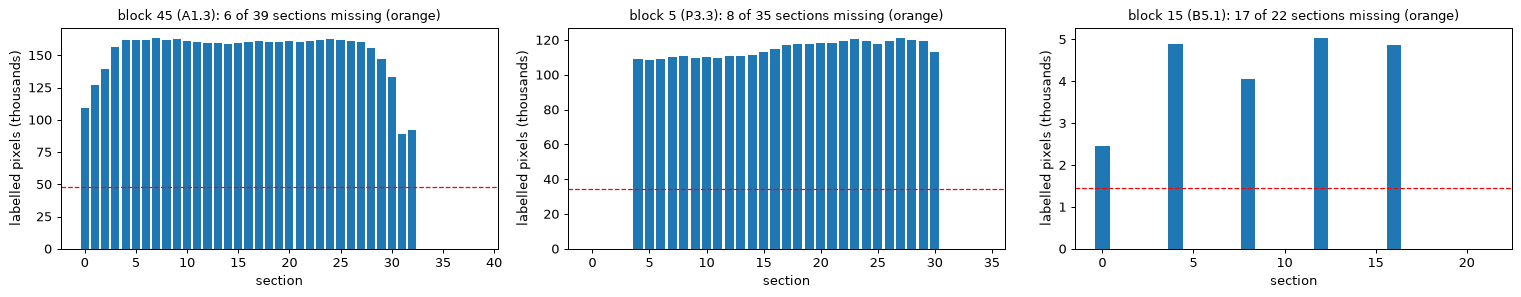

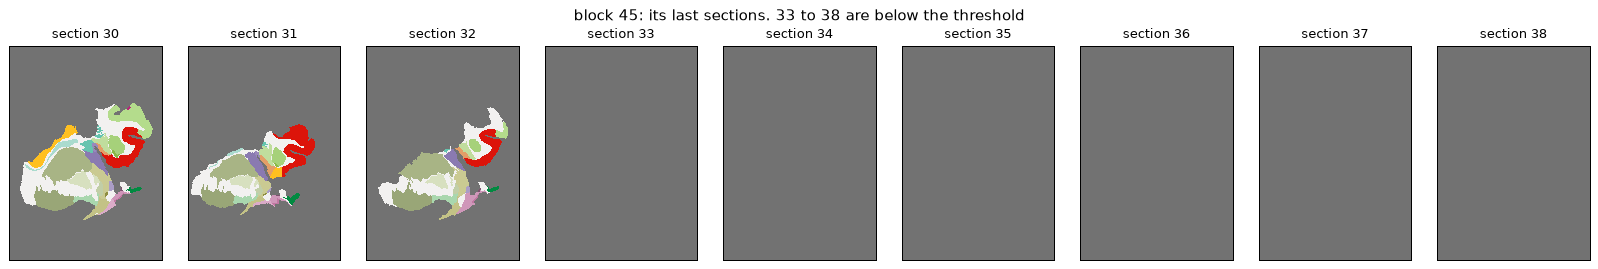

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(17, 3.4))
for ax, b in zip(axs, (45, 5, 15)):
    L3 = np.asanyarray(load_block(b).dataobj)
    area = (L3 > 0).sum(axis=(0, 1)); thr = MIN_SECTION_FRAC * np.median(area[area > 0])
    ok = area >= thr
    ax.bar(np.arange(len(area)), area / 1e3, color=np.where(ok, "tab:blue", "tab:orange"))
    ax.axhline(thr / 1e3, color="r", ls="--", lw=1); ax.set_xlabel("section"); ax.set_ylabel("labelled pixels (thousands)")
    ax.set_title(f"block {b} ({block_name[str(b)]}): {int((~ok).sum())} of {len(area)} sections missing (orange)", fontsize=10)
plt.tight_layout(); plt.show()

L45 = np.asanyarray(load_block(45).dataobj)
fig, axs = plt.subplots(1, 9, figsize=(18, 3))
for ax, k in zip(axs, range(30, 39)):
    show_lab(ax, L45[::4, ::4, k], title=f"section {k}"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("block 45: its last sections. 33 to 38 are below the threshold"); plt.tight_layout(); plt.show()

- Block 45: the last six sections are empty.
- Block 5: missing sections at both ends.
- Block 15 (a brainstem block): only one section out of four was segmented. Version 1 writes thin
  labelled sheets separated by empty space; version 2 interpolates between the labelled ones.

### Bracketing sections

For every output voxel the script knows its continuous position `zc` along the stack (in section
units, see the first notebook). With the sorted list `valid` it finds the usable section just below
(`s_lo`) and just above (`s_hi`) using `np.searchsorted`, and then:

```
span    = s_hi - s_lo
t       = (zc - s_lo) / span              # 0 if span = 0
dist    = min(|zc - s_lo|, |zc - s_hi|) * dz      # mm to the nearest USABLE section
bridged = span != 1                       # not between two consecutive sections
```

- `span = 1`: normal case, between two consecutive sections → **interpolated**.
- `span > 1`: one or more missing sections in between → interpolated across the hole → **bridged**.
- `span = 0`: before the first or after the last usable section → that section is **copied**
  (also flagged bridged). This is what fills the gap at the end of a block.

Same lines as the script, for a few positions in block 45:

In [11]:
img45 = load_block(45); dz45 = float(np.linalg.norm(img45.affine[:3, 2]))
area = (L45 > 0).sum(axis=(0, 1))
valid = np.flatnonzero(area >= MIN_SECTION_FRAC * np.median(area[area > 0]))
print("valid sections:", valid.tolist(), "\n")

zc = np.array([-0.4, 0.3, 12.5, 31.8, 32.0, 32.6, 35.0, 38.4])
j = np.searchsorted(valid, zc)
s_lo = valid[np.clip(j - 1, 0, len(valid) - 1)]
s_hi = valid[np.clip(j, 0, len(valid) - 1)]
s_lo = np.where(zc < valid[0], valid[0], s_lo)
s_hi = np.where(zc > valid[-1], valid[-1], s_hi)
span = s_hi - s_lo
t = np.where(span > 0, (zc - s_lo) / np.maximum(span, 1), 0)
dist = np.minimum(np.abs(zc - s_lo), np.abs(zc - s_hi)) * dz45
bridged = span != 1
print("    zc | s_lo s_hi |    t  | dist (mm) | what happens")
for q in range(len(zc)):
    what = ("copy section %d" % s_lo[q]) if span[q] == 0 else ("interpolate %d-%d" % (s_lo[q], s_hi[q]))
    print(f"  {zc[q]:5.1f} | {s_lo[q]:3d}  {s_hi[q]:3d}  | {t[q]:.2f}  |   {dist[q]:.2f}    | {what}{'  (bridged)' if bridged[q] else ''}")

valid sections: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32] 

    zc | s_lo s_hi |    t  | dist (mm) | what happens
   -0.4 |   0    0  | 0.00  |   0.15    | copy section 0  (bridged)
    0.3 |   0    1  | 0.30  |   0.11    | interpolate 0-1
   12.5 |  12   13  | 0.50  |   0.19    | interpolate 12-13
   31.8 |  31   32  | 0.80  |   0.07    | interpolate 31-32
   32.0 |  31   32  | 1.00  |   0.00    | interpolate 31-32
   32.6 |  32   32  | 0.00  |   0.22    | copy section 32  (bridged)
   35.0 |  32   32  | 0.00  |   1.11    | copy section 32  (bridged)
   38.4 |  32   32  | 0.00  |   2.37    | copy section 32  (bridged)


Two remarks:
- A voxel that falls exactly on a section (`zc = 32.0`) is given `s_lo = 31, s_hi = 32, t = 1`: the
  result is section 32 itself. Sections are reproduced exactly.
- Voxels after the last usable section copy it straight along the section axis, up to the end of
  the block (here up to 6 sections x 0.37 mm = 2.4 mm). The copy is a flat extrusion: it closes the
  gap but does not follow how the anatomy changes there. `dist` grows with the distance, so in the
  mosaic the neighbouring block wins as soon as it has a section that is closer.

**Limit:** the test is on the whole section. A section that is 60% labelled is "usable", and the
40% that is missing stays empty in the output. This is why some thin gaps remain at block borders.

## 6. One whole block: `reconstruct_block`

`reconstruct_block` does sections 2-5 for all the output voxels of a block:
1. bounding box of the block in the output grid and the affine `M` (as in version 1);
2. `valid` sections;
3. for every voxel inside the block: in-plane pixel `(xi, yi)`, bracketing sections, `t`, `dist`, `bridged`;
4. the voxels are **grouped by pair of sections** `(s_lo, s_hi)`. For each group the distance maps
   of the two sections are computed (and cached: a section is shared by two consecutive pairs) and
   the label with the largest blended value is kept;
5. it returns the box, the labels, `dist` and `bridged`.

Computing the distance maps is what makes version 2 slower (about 7 minutes for a case instead of
45 seconds): one map per label and per section, at 0.1 mm.

block 8: {'n_sections': 18, 'n_missing': 3, 'dz': 0.7180755215291006, 'n_labels': 16}  (8 s)
labelled voxels: version 1 1556579, version 2 1898585
voxels with a different label: 400670 (21.1% of the block)


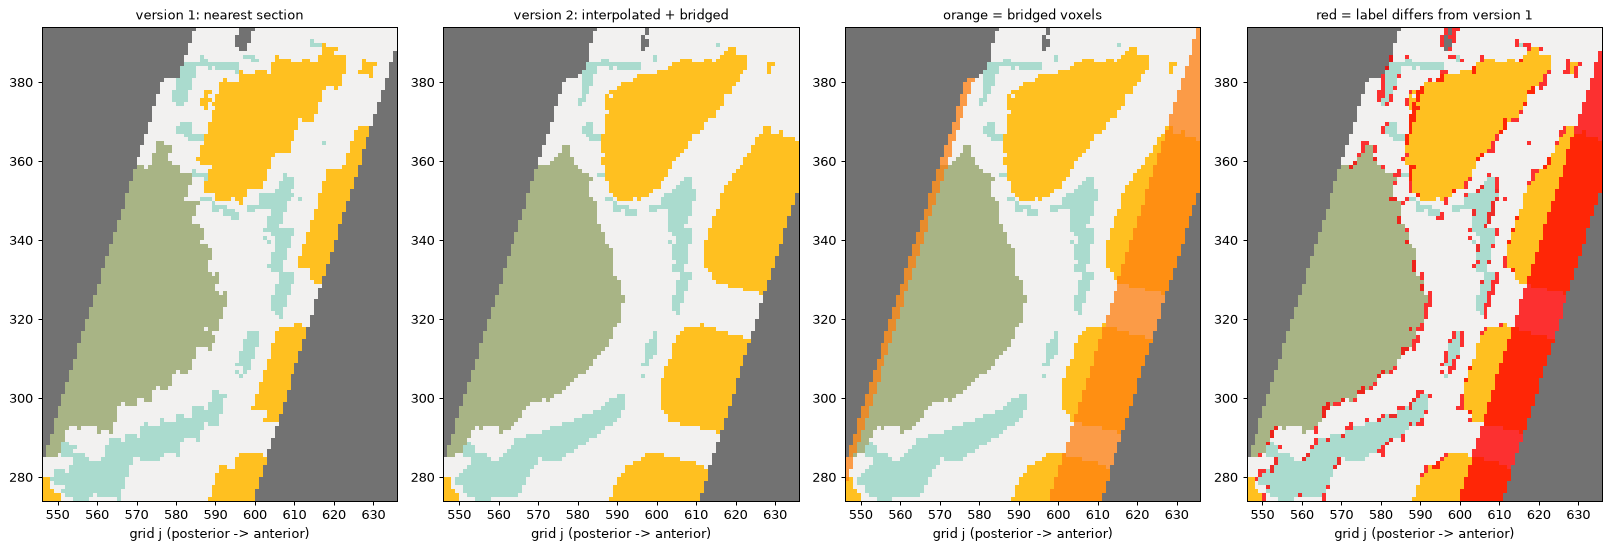

In [12]:
t0 = time.time()
box2, v2_blk, v2_dist, v2_bridged, info = V2.reconstruct_block(lab, img.affine, shape, affine, RES,
                                                               MIN_SECTION_FRAC, SDT_CAP_MM, STRIDE)
print(f"block {EXAMPLE}: {info}  ({time.time()-t0:.0f} s)")
assert box2 == box1
print(f"labelled voxels: version 1 {(v1_blk > 0).sum()}, version 2 {(v2_blk > 0).sum()}")
print(f"voxels with a different label: {(v1_blk != v2_blk).sum()} "
      f"({(v1_blk != v2_blk).sum() / (v2_blk > 0).sum() * 100:.1f}% of the block)")

fig, axs = plt.subplots(1, 4, figsize=(18, 7))
show_lab(axs[0], v1_blk[IX][ZJ, ZK], gext(ZJ, ZK), "version 1: nearest section")
show_lab(axs[1], v2_blk[IX][ZJ, ZK], gext(ZJ, ZK), "version 2: interpolated + bridged")
show_lab(axs[2], v2_blk[IX][ZJ, ZK], gext(ZJ, ZK), "orange = bridged voxels"); overlay(axs[2], (v2_bridged & (v2_blk > 0))[IX][ZJ, ZK], "tab:orange", gext(ZJ, ZK), 0.75)
show_lab(axs[3], v2_blk[IX][ZJ, ZK], gext(ZJ, ZK), "red = label differs from version 1"); overlay(axs[3], (v1_blk != v2_blk)[IX][ZJ, ZK], "red", gext(ZJ, ZK), 0.8)
for ax in axs: ax.set_xlabel("grid j (posterior -> anterior)")
plt.tight_layout(); plt.show()

- The steps of the staircase are replaced by smooth, slanted borders.
- The last sections of the block (missing in the file) are now filled by copying the last usable
  section (orange).
- The changes are concentrated along the borders between structures; the interior is identical.

## 7. Mosaic of several blocks and the `steps` map

The blocks are then pasted on the common grid exactly as in version 1:

```
take = (lab > 0) & (dist < best[box])      # labelled AND nearer to a usable section than what is there
seg[box][take]   = lab[take]
best[box][take]  = dist[take]
steps[box][take] = 2 if bridged else 1
```

The only difference is that `dist` is now the distance to the nearest **usable** section. A voxel
copied from far away (bridged over several missing sections) has a large `dist`, so real data from
a neighbouring block always replaces it.

`steps` is saved next to the segmentation (`*_v2_steps.nii.gz`) to know how each voxel was obtained:
1 interpolated, 2 bridged, 3 MRI fill, 4 trimmed.

The full script does this for the 45 blocks. Here four neighbouring blocks are enough to see it
(A2.3, A1.3, P1.3, P2.2, from front to back).

In [13]:
SUBSET = [8, 45, 33, 41]
seg = np.zeros(shape, np.uint16); steps = np.zeros(shape, np.uint8); best = np.full(shape, np.inf, np.float32)
seg1 = np.zeros(shape, np.uint16); best1 = np.full(shape, np.inf, np.float32)      # version 1 on the same blocks
t0 = time.time()
for b in SUBSET:
    im = load_block(b)
    box, lab_b, dist_b, bridged_b, inf = V2.reconstruct_block(np.asanyarray(im.dataobj), im.affine, shape, affine, RES,
                                                              MIN_SECTION_FRAC, SDT_CAP_MM, STRIDE)
    take = (lab_b > 0) & (dist_b < best[box])
    seg[box][take] = lab_b[take]
    best[box][take] = dist_b[take]
    steps[box][take] = np.where(bridged_b[take], V2.STEP_BRIDGED, V2.STEP_INTERP)
    print(f"block {b:>2} ({block_name[str(b)]}): {inf['n_sections']} sections ({inf['n_missing']} missing), "
          f"spacing {inf['dz']:.2f} mm, {inf['n_labels']} labels, {int(take.sum())} voxels written")
    bx, va, da = resample_block_v1(im)
    tk = (va > 0) & (da < best1[bx]); seg1[bx][tk] = va[tk]; best1[bx][tk] = da[tk]
del best, best1
print(f"{time.time()-t0:.0f} s | labelled voxels: version 1 {(seg1 > 0).sum()}, version 2 {(seg > 0).sum()}")

block  8 (A2.3): 18 sections (3 missing), spacing 0.72 mm, 16 labels, 1898585 voxels written


block 45 (A1.3): 39 sections (6 missing), spacing 0.37 mm, 136 labels, 2414941 voxels written


block 33 (P1.3): 36 sections (3 missing), spacing 0.36 mm, 125 labels, 2078363 voxels written


block 41 (P2.2): 36 sections (4 missing), spacing 0.37 mm, 85 labels, 1872827 voxels written


201 s | labelled voxels: version 1 7653350, version 2 8157109


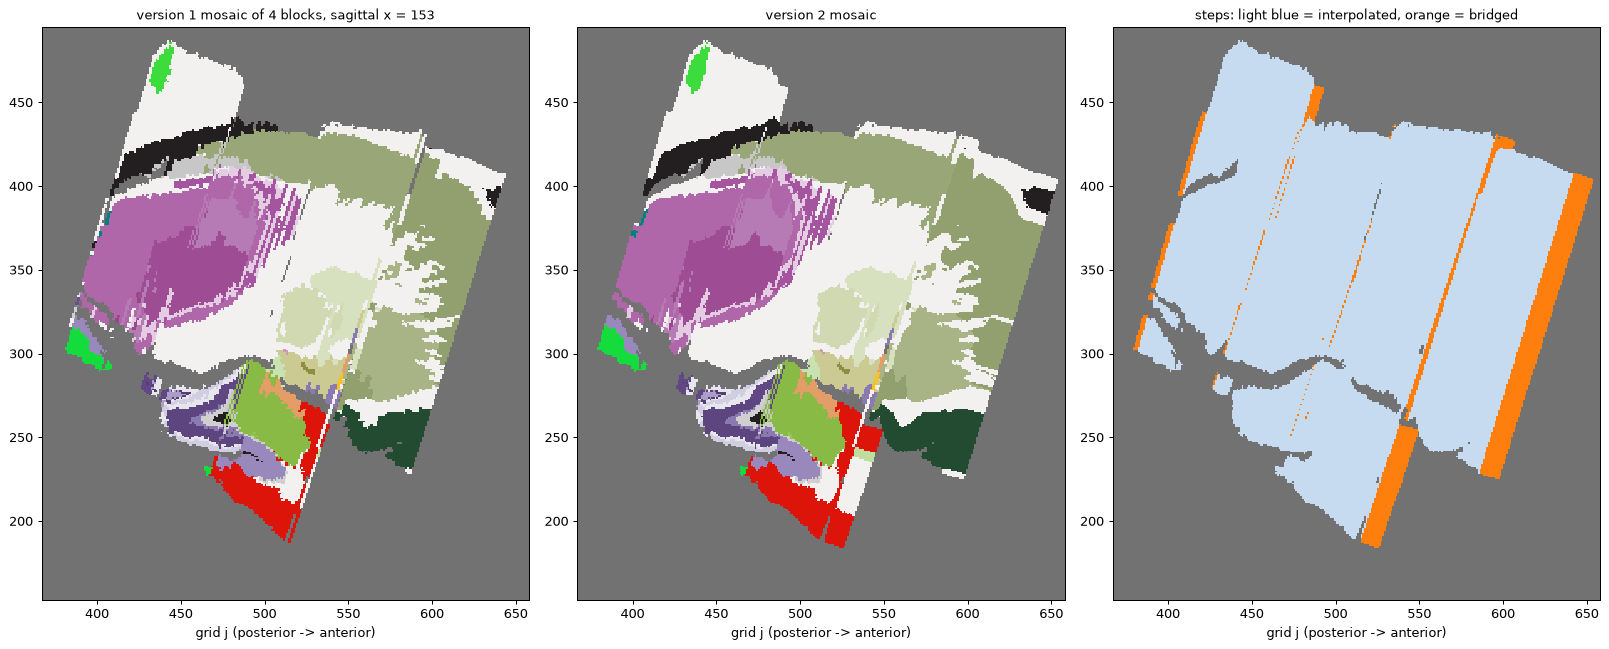

In [14]:
# crop of the grid that contains the four blocks
nz = [np.nonzero((seg > 0).any(axis=tuple(a for a in range(3) if a != ax)))[0] for ax in range(3)]
CROP = tuple(slice(int(a[0]), int(a[-1]) + 1) for a in nz)
SX = int(np.percentile(nz[0], 40))
cs = lambda vol: vol[SX][CROP[1], CROP[2]]
e = ext_of(CROP[1], CROP[2])
fig, axs = plt.subplots(1, 3, figsize=(18, 9))
show_lab(axs[0], cs(seg1), e, f"version 1 mosaic of 4 blocks, sagittal x = {SX}")
show_lab(axs[1], cs(seg), e, "version 2 mosaic")
show_img(axs[2], cs(steps), e, "steps: light blue = interpolated, orange = bridged", cmap=STEP_CMAP, vmin=0, vmax=4)
for ax in axs: ax.set_xlabel("grid j (posterior -> anterior)")
plt.tight_layout(); plt.show()

The tilted unlabelled lines between the blocks in version 1 (left) are the block gaps. In version 2
most of them are closed, and the `steps` map shows that they were closed by bridging (orange),
i.e. by extending the last usable section of a block.

What is still open after this step: holes that exist in the sections themselves, partly labelled
sections (see the limit in section 5), and of course the sulci, which are real.

## 8. Trimming with the MRI

Until here the MRI was only used for its grid. Now its content is used: a label where **the MRI is
zero** is outside the brain (a small registration error at the surface, or a bridged section that
extends too far), so it is removed.

The mask is built on the output grid like in the script: the binary image `MRI > 0` is resampled
with trilinear interpolation and thresholded at 0.5.

In [15]:
M = np.linalg.inv(mri.affine) @ affine
mri_data = np.asanyarray(mri.dataobj)
tissue = ndi.affine_transform((mri_data > 0).astype(np.float32), M[:3, :3], M[:3, 3],
                              output_shape=shape, order=1, mode="constant", cval=0) >= 0.5        # as in the script
mri_grid = ndi.affine_transform(mri_data.astype(np.float32), M[:3, :3], M[:3, 3], output_shape=shape, order=1)   # display only
print(f"MRI > 0: {tissue.sum()*RES**3/1000:.1f} cm3")
outside_any = (seg > 0) & ~tissue
print(f"in the 4-block mosaic, {outside_any.sum()} labelled voxels ({outside_any.sum()*RES**3/1000:.2f} cm3) are where the MRI is zero")

MRI > 0: 549.4 cm3


in the 4-block mosaic, 377912 labelled voxels (3.02 cm3) are where the MRI is zero


### Labels that the MRI cannot see

Removing everything where the MRI is zero would be wrong. In this MRI the **ventricles are zero**,
and some structures are simply **not in the stripped MRI** (optic nerve, pineal body, midline
structures of the other side...). In the first test of version 2, 78% of the lateral ventricle and
several whole labels were deleted this way.

The script therefore measures, for each label, the fraction of its volume that lies where the MRI
is zero. If it is above `--keep-outside-frac` (0.25) the label is declared **not visible in the
MRI** and is never trimmed. A label that is really inside the brain has only a thin shell outside
(a few %), so the two groups are well separated.

In [16]:
tot = np.bincount(seg.ravel(), minlength=int(seg.max()) + 1)
outside = np.bincount(seg[~tissue], minlength=len(tot))
not_in_mri = np.zeros(len(tot), bool)
not_in_mri[1:] = outside[1:] > KEEP_OUTSIDE_FRAC * np.maximum(tot[1:], 1)

frac = outside / np.maximum(tot, 1)
order = [l for l in np.argsort(frac)[::-1] if tot[l] > 0 and l > 0][:14]
print("label                                              volume mm3   fraction where MRI = 0")
for l in order:
    print(f"  {l:5d} {NAMES.get(int(l), '?')[:42]:42s} {tot[l]*RES**3:9.1f}   {frac[l]:.2f}   {'-> kept (not visible in MRI)' if not_in_mri[l] else ''}")
present = np.flatnonzero(tot[1:] > 0) + 1
print(f"\n{not_in_mri.sum()} of {len(present)} labels of these 4 blocks are exempt. "
      f"Median fraction outside for the other labels: {np.median(frac[present][~not_in_mri[present]]):.3f}")

label                                              volume mm3   fraction where MRI = 0
    493 habenular_commissure                             1.4   1.00   -> kept (not visible in MRI)
    470 subcommissural_organ                             2.0   1.00   -> kept (not visible in MRI)
    506 pineal_body                                      1.0   1.00   -> kept (not visible in MRI)
    114 optic_nerve                                    102.0   1.00   -> kept (not visible in MRI)
    472 posterior_commissure                            15.4   0.98   -> kept (not visible in MRI)
     68 septum_pellucidum                               26.4   0.94   -> kept (not visible in MRI)
    465 periaqueductal_gray_substance                    6.4   0.84   -> kept (not visible in MRI)
     50 anterior_horn_of_lateral_ventricle            2893.6   0.72   -> kept (not visible in MRI)
    447 edinger-westphal_nucleus_(accessory_oculom       0.8   0.60   -> kept (not visible in MRI)
    843 infundibular_s

removed: 85325 voxels (0.68 cm3); kept although MRI = 0: 292587 voxels


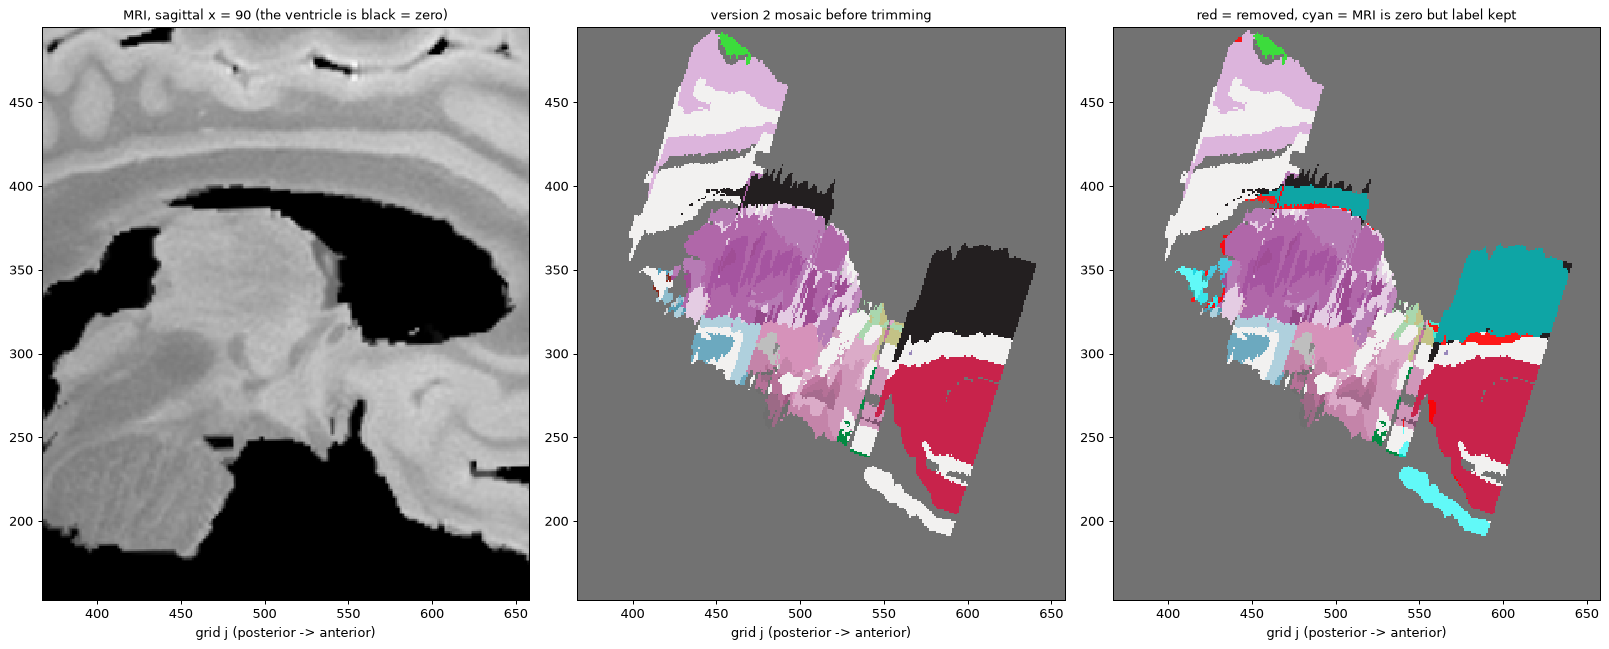

In [17]:
trim = (seg > 0) & ~tissue & ~not_in_mri[seg]              # the line of the script
kept_out = (seg > 0) & ~tissue & not_in_mri[seg]
print(f"removed: {trim.sum()} voxels ({trim.sum()*RES**3/1000:.2f} cm3); kept although MRI = 0: {kept_out.sum()} voxels")

ST = int(np.argmax((trim | kept_out).sum(axis=(1, 2))))    # sagittal slice with most voxels where MRI = 0
ct = lambda vol: vol[ST][CROP[1], CROP[2]]
e = ext_of(CROP[1], CROP[2])
fig, axs = plt.subplots(1, 3, figsize=(18, 8))
show_img(axs[0], ct(mri_grid), e, f"MRI, sagittal x = {ST} (the ventricle is black = zero)", cmap="gray")
show_lab(axs[1], ct(seg), e, "version 2 mosaic before trimming")
show_lab(axs[2], ct(seg), e, "red = removed, cyan = MRI is zero but label kept")
overlay(axs[2], ct(trim), "red", e); overlay(axs[2], ct(kept_out), "cyan", e, 0.6)
for ax in axs: ax.set_xlabel("grid j (posterior -> anterior)")
plt.tight_layout(); plt.show()

seg[trim] = 0; steps[trim] = V2.STEP_TRIM

Red voxels are labels lying where the MRI has no signal; they are removed. The cyan voxels are
also where the MRI is zero, but they belong to exempt labels (ventricle, midline structures) and are kept.

## 9. The optional MRI fill, and why it is off

It is tempting to do the opposite too: give a label to every voxel **inside the brain** that is
still unlabelled (nearest label in 3D, up to `--max-fill-mm`). The code is in the script
(`--mri-fill`) but it is **off by default**, because of what the MRI mask really is:

`mri_rotated/mri.nii.gz` is only **brain-masked**. The space inside the sulci is not zero: it is
as bright as the cortex. So `MRI > 0` is a mask of "brain + sulci", not of tissue, and filling it
**closes the sulci**. The first version 2 output had this problem.

The cell below applies the fill of the script to a coronal slab of the **complete** version 2
output (the file written by the script, loaded here) to show it.

In [18]:
del seg1
full2 = np.asanyarray(nib.load(OUT_V2).dataobj)
fgy = np.nonzero((full2 > 0).any(axis=(0, 2)))[0]; FY = int(fgy.mean())

# labels not visible in the MRI, on the whole volume (same rule as section 8)
tot_f = np.bincount(full2.ravel(), minlength=int(full2.max()) + 1)
nim = np.zeros(len(tot_f), bool)
nim[1:] = np.bincount(full2[~tissue], minlength=len(tot_f))[1:] > KEEP_OUTSIDE_FRAC * np.maximum(tot_f[1:], 1)

pad = int(np.ceil(MAX_FILL_MM / RES)) + 2
slab = (slice(None), slice(FY - pad, FY + pad + 1), slice(None))       # thin coronal slab around y = FY
before = full2[slab]
sub = before.copy()
todo = tissue[slab] & (sub == 0)
d, ind = ndi.distance_transform_edt((sub == 0) | nim[sub], sampling=(RES,) * 3, return_indices=True)   # lines of the script
fill = todo & (d <= MAX_FILL_MM)
sub[fill] = sub[tuple(i[fill] for i in ind)]
del d, ind

m_slab = mri_grid[slab]
print(f"in this slab the fill adds {fill.sum()} voxels to the {(before > 0).sum()} labelled ones (+{fill.sum() / (before > 0).sum() * 100:.0f}%); "
      f"{(sub[fill] >= 2000).mean()*100:.0f}% of them get a cortical label")
print(f"median MRI intensity: filled voxels {np.median(m_slab[fill]):.0f} | cortex {np.median(m_slab[before >= 2000]):.0f} "
      f"| white matter {np.median(m_slab[before == 7]):.0f} | outside the mask 0")

in this slab the fill adds 204841 voxels to the 2999958 labelled ones (+7%); 73% of them get a cortical label
median MRI intensity: filled voxels 130 | cortex 129 | white matter 107 | outside the mask 0


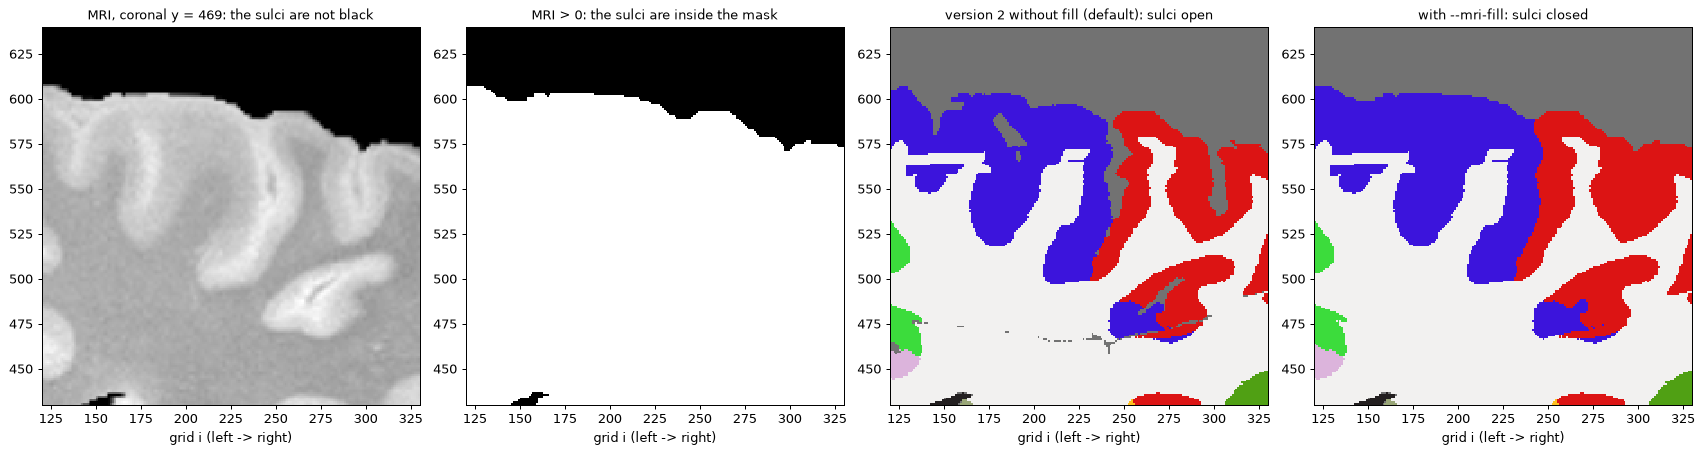

In [19]:
WI, WK2 = slice(120, 330), slice(430, 640)
e = ext_of(WI, WK2)
fig, axs = plt.subplots(1, 4, figsize=(19, 5.6))
show_img(axs[0], m_slab[:, pad][WI, WK2], e, f"MRI, coronal y = {FY}: the sulci are not black", cmap="gray")
show_img(axs[1], tissue[:, FY][WI, WK2], e, "MRI > 0: the sulci are inside the mask", cmap="gray")
show_lab(axs[2], before[:, pad][WI, WK2], e, "version 2 without fill (default): sulci open")
show_lab(axs[3], sub[:, pad][WI, WK2], e, "with --mri-fill: sulci closed")
for ax in axs: ax.set_xlabel("grid i (left -> right)")
plt.tight_layout(); plt.show()

The filled voxels are not dark in the MRI: their intensity is in the range of the tissue, so the
MRI mask gives no way to tell a sulcus from a hole in the cortex. The option is only safe with a
real tissue mask (one where the sulci are background), which this dataset does not provide directly.

So in the default version 2, holes and cracks inside the tissue stay open. They are left to a
method that knows about sulci, such as `dev/wp2/fill_holes/manual/restore.py`.

## 10. The complete result

```bash
python build_3d_segmentation_v2.py --case-dir ../NextBrain-Case-1/P57-16 --res 0.2
# -> outputs/P57-16_seg_0.2mm_v2.nii.gz          labels
# -> outputs/P57-16_seg_0.2mm_v2_steps.nii.gz    1 interpolated, 2 bridged, 3 MRI fill, 4 trimmed
# about 7 minutes
```

Other options: `--like ref.nii.gz` writes on the grid of another volume, `--no-trim` skips section 8,
`--inplane-stride 2` uses one pixel out of two (faster, less detail), `--min-section-frac`,
`--sdt-cap-mm`, `--keep-outside-frac`, `--mri-fill` / `--max-fill-mm` as explained above.

The cells below load the two files produced by the scripts and compare them.

In [20]:
full1 = np.asanyarray(nib.load(OUT_V1).dataobj)
fsteps = np.asanyarray(nib.load(OUT_V2.replace(".nii.gz", "_steps.nii.gz")).dataobj)
vox = RES ** 3 / 1000
print(f"version 1: {len(np.unique(full1)) - 1} labels, {(full1 > 0).sum()*vox:.1f} cm3")
print(f"version 2: {len(np.unique(full2)) - 1} labels, {(full2 > 0).sum()*vox:.1f} cm3")
for s, name in STEP_NAMES.items():
    n = int((fsteps == s).sum()); print(f"  steps = {s} ({name:12s}): {n:10d} voxels = {n*vox:6.1f} cm3")
same = (full1 == full2)
print(f"voxels labelled in both with the same label: {(same & (full1 > 0)).sum() / ((full1 > 0) & (full2 > 0)).sum() * 100:.1f}%")
print(f"labelled in version 2 only: {((full2 > 0) & (full1 == 0)).sum()*vox:.1f} cm3 | in version 1 only: {((full1 > 0) & (full2 == 0)).sum()*vox:.1f} cm3")

version 1: 333 labels, 516.5 cm3


version 2: 333 labels, 515.0 cm3


  steps = 1 (interpolated):   62056183 voxels =  496.4 cm3


  steps = 2 (bridged     ):    2316681 voxels =   18.5 cm3


  steps = 3 (MRI fill    ):          0 voxels =    0.0 cm3


  steps = 4 (trimmed     ):    1222013 voxels =    9.8 cm3


voxels labelled in both with the same label: 97.4%


labelled in version 2 only: 9.9 cm3 | in version 1 only: 11.4 cm3


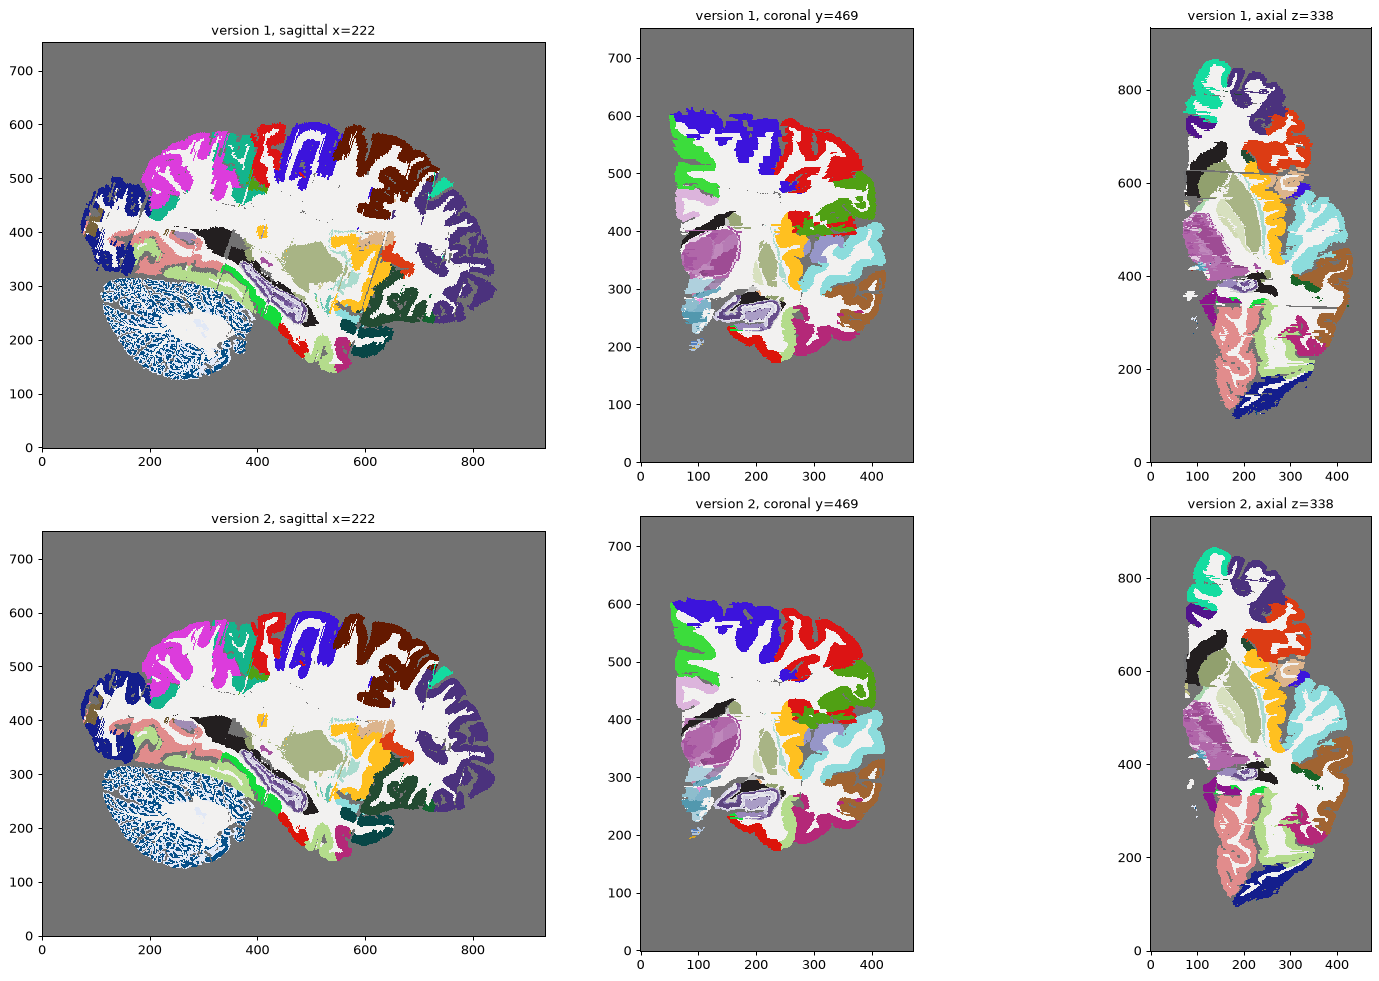

In [21]:
fgx = np.nonzero((full2 > 0).any(axis=(1, 2)))[0]; fgz = np.nonzero((full2 > 0).any(axis=(0, 1)))[0]
FX, FZ = int(np.percentile(fgx, 45)), int(fgz.mean())
fig, axs = plt.subplots(2, 3, figsize=(17, 11))
for col, (name, a1, a2) in enumerate([(f"sagittal x={FX}", full1[FX], full2[FX]), (f"coronal y={FY}", full1[:, FY], full2[:, FY]),
                                      (f"axial z={FZ}", full1[:, :, FZ], full2[:, :, FZ])]):
    show_lab(axs[0, col], a1, title="version 1, " + name); show_lab(axs[1, col], a2, title="version 2, " + name)
plt.tight_layout(); plt.show()

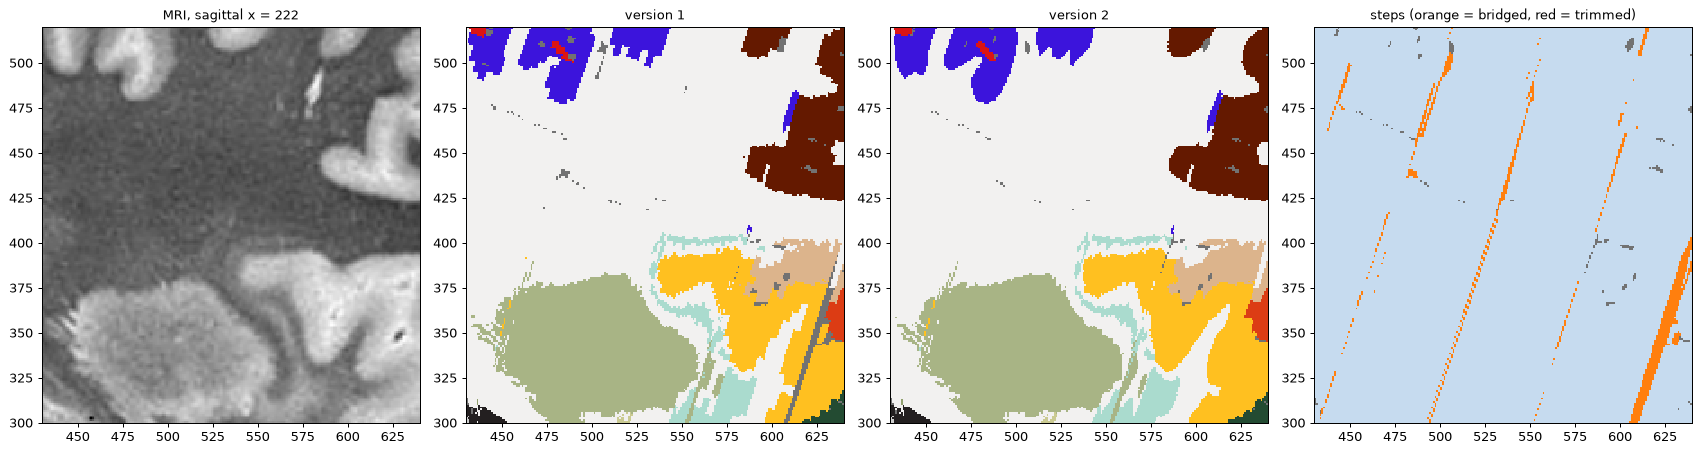

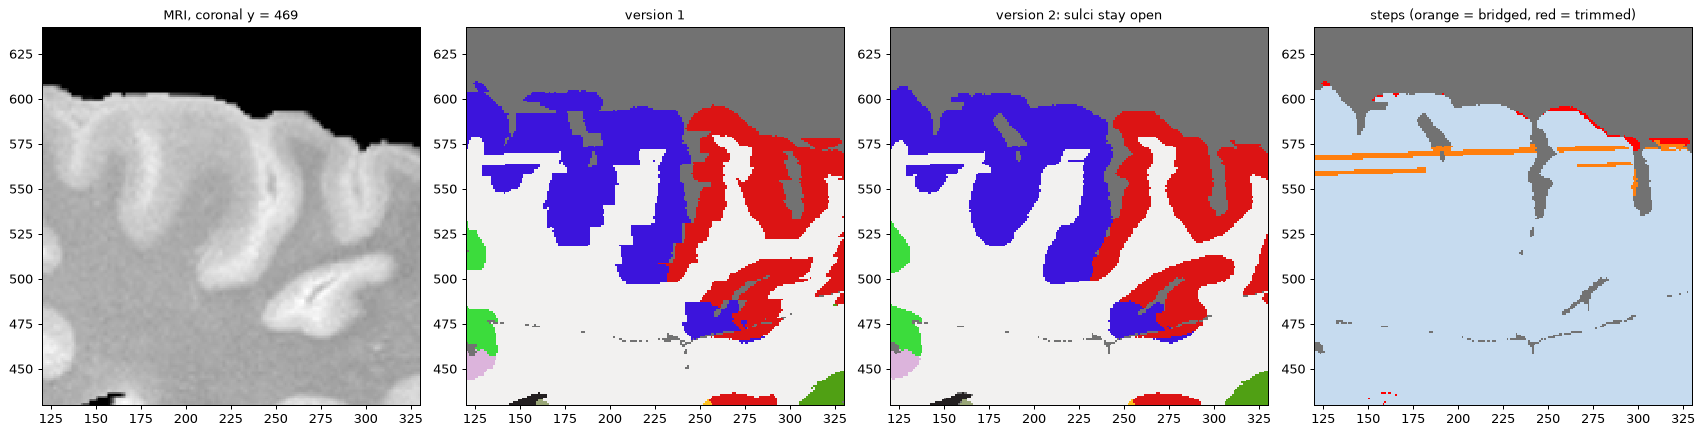

In [22]:
WJ, WK = slice(430, 640), slice(300, 520)
e = ext_of(WJ, WK)
fig, axs = plt.subplots(1, 4, figsize=(19, 5.6))
show_img(axs[0], mri_grid[FX][WJ, WK], e, f"MRI, sagittal x = {FX}", cmap="gray")
show_lab(axs[1], full1[FX][WJ, WK], e, "version 1"); show_lab(axs[2], full2[FX][WJ, WK], e, "version 2")
show_img(axs[3], fsteps[FX][WJ, WK], e, "steps (orange = bridged, red = trimmed)", cmap=STEP_CMAP, vmin=0, vmax=4)
plt.tight_layout(); plt.show()

e = ext_of(WI, WK2)
fig, axs = plt.subplots(1, 4, figsize=(19, 5.6))
show_img(axs[0], mri_grid[:, FY][WI, WK2], e, f"MRI, coronal y = {FY}", cmap="gray")
show_lab(axs[1], full1[:, FY][WI, WK2], e, "version 1"); show_lab(axs[2], full2[:, FY][WI, WK2], e, "version 2: sulci stay open")
show_img(axs[3], fsteps[:, FY][WI, WK2], e, "steps (orange = bridged, red = trimmed)", cmap=STEP_CMAP, vmin=0, vmax=4)
plt.tight_layout(); plt.show()

### What was measured on Case 1

There is no ground truth for these hemispheres, so the two versions were compared on quantities
that can be checked (cortical parcels merged into one label for these numbers):

| measure | version 1 | version 2 |
|---|---|---|
| labels present | 333 | 333 |
| labelled volume | 516.5 cm³ | 515.0 cm³ |
| MRI intensity variance explained by the labels (higher = labels follow the MRI better) | 0.475 | 0.487 |
| labels where the MRI is zero | 8.0 cm³ | 4.9 cm³ |
| thin unlabelled runs (≤ 2.4 mm, front-back) between two white-matter voxels | 177,651 voxels | 93,794 voxels |
| thin unlabelled runs between two non-cortical voxels | 1,115,461 voxels | 871,978 voxels |
| thin unlabelled runs between two cortical voxels (mostly sulci) | 2,468,532 voxels | 1,843,743 voxels |
| enclosed unlabelled cavities | 206,531 voxels | 180,202 voxels |
| run time | 45 s | 7 min |

How to read it:
- Version 2 follows the MRI slightly better and removes about half of the white-matter gaps.
- It does **not** remove all the gaps, and the enclosed holes are almost unchanged.
- The runs between cortical voxels dropped by 25%. Part of them are block gaps crossing the cortex,
  but part may be **sulci made narrower** by bridging (a flat copy of a section across a sulcus that
  runs parallel to the sections). This has not been separated; check the sulci near block borders.
- A few small labels change volume a lot (optic chiasm ×3.3, spinal accessory nucleus ×4.6; three
  tiny labels lose 34-50%), mostly because of bridging.

### What version 2 does not do

| artefact | status |
|---|---|
| staircase | reduced by the interpolation (limited by the 1 mm cap for fast-moving structures) |
| block gaps | closed where whole sections are missing; **not** where sections are partly labelled |
| holes and cracks inside the tissue | not treated (the MRI cannot separate them from sulci) |
| block steps (misalignment between blocks) | not treated: it is a registration error, the script trusts the affines |
| sulci | kept open by default; closed if `--mri-fill` is used |

For gaps, cracks and holes, `restore.py` applied to this output is the natural next step: on the
same case it leaves about four times fewer white-matter gap voxels than version 2 alone.